In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data = pd.read_csv('/content/new_insurance_data_linear_regression.csv')
df = data
df

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
0,18.0,male,23.210,0.0,no,29087.54313,17.0,715428.0,4.720921e+06,0.0,5.578497e+07,southeast,1121.87390
1,18.0,male,30.140,0.0,no,39053.67437,7.0,699157.0,4.329832e+06,0.0,1.370089e+07,southeast,1131.50660
2,18.0,male,33.330,0.0,no,39023.62759,19.0,702341.0,6.884861e+06,0.0,7.352311e+07,southeast,1135.94070
3,18.0,male,33.660,0.0,no,28185.39332,11.0,700250.0,4.274774e+06,0.0,7.581968e+07,southeast,1136.39940
4,18.0,male,34.100,0.0,no,14697.85941,16.0,711584.0,3.787294e+06,0.0,2.301232e+07,southeast,1137.01100
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,33.0,female,35.530,0.0,yes,63142.25346,32.0,1091267.0,1.703805e+08,2.0,3.101107e+09,northwest,55135.40209
1334,31.0,female,38.095,1.0,yes,43419.95227,31.0,1107872.0,2.015152e+08,2.0,3.484216e+09,northeast,58571.07448
1335,52.0,male,34.485,3.0,yes,52458.92353,25.0,1092005.0,2.236450e+08,2.0,3.640807e+09,northwest,60021.39897
1336,45.0,male,30.360,0.0,yes,69927.51664,34.0,1106821.0,2.528924e+08,3.0,4.006359e+09,southeast,62592.87309


In [ ]:
df.head()

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
0,18.0,male,23.21,0.0,no,29087.54313,17.0,715428.0,4720920.992,0.0,55784970.05,southeast,1121.8739
1,18.0,male,30.14,0.0,no,39053.67437,7.0,699157.0,4329831.676,0.0,13700885.19,southeast,1131.5066
2,18.0,male,33.33,0.0,no,39023.62759,19.0,702341.0,6884860.774,0.0,73523107.27,southeast,1135.9407
3,18.0,male,33.66,0.0,no,28185.39332,11.0,700250.0,4274773.550,0.0,75819679.60,southeast,1136.3994
4,18.0,male,34.10,0.0,no,14697.85941,16.0,711584.0,3787293.921,0.0,23012320.01,southeast,1137.0110


In [ ]:
df.tail()

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
1333,33.0,female,35.530,0.0,yes,63142.25346,32.0,1091267.0,170380500.5,2.0,3.101107e+09,northwest,55135.40209
1334,31.0,female,38.095,1.0,yes,43419.95227,31.0,1107872.0,201515184.8,2.0,3.484216e+09,northeast,58571.07448
1335,52.0,male,34.485,3.0,yes,52458.92353,25.0,1092005.0,223644981.3,2.0,3.640807e+09,northwest,60021.39897
1336,45.0,male,30.360,0.0,yes,69927.51664,34.0,1106821.0,252892382.6,3.0,4.006359e+09,southeast,62592.87309
1337,54.0,female,47.410,0.0,yes,63982.80926,31.0,1100328.0,261631699.3,3.0,4.117197e+09,southeast,63770.42801


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 13 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   age                              1329 non-null   float64
 1   sex                              1338 non-null   object 
 2   bmi                              1335 non-null   float64
 3   children                         1333 non-null   float64
 4   smoker                           1338 non-null   object 
 5   Claim_Amount                     1324 non-null   float64
 6   past_consultations               1332 non-null   float64
 7   num_of_steps                     1335 non-null   float64
 8   Hospital_expenditure             1334 non-null   float64
 9   NUmber_of_past_hospitalizations  1336 non-null   float64
 10  Anual_Salary                     1332 non-null   float64
 11  region                           1338 non-null   object 
 12  charges             

In [ ]:
df.iloc[50:71]

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
50,18.0,male,23.085,0.0,no,8776.995213,3.0,752756.0,1738321.863,0.0,3.550884e+06,northeast,1704.70015
51,18.0,male,23.750,0.0,no,18755.363010,5.0,746292.0,9902819.926,0.0,9.678199e+07,northeast,1705.62450
52,18.0,male,25.460,0.0,no,39131.903860,13.0,730943.0,9008707.699,0.0,3.774956e+07,northeast,1708.00140
53,18.0,male,26.125,0.0,no,10782.263260,13.0,741524.0,4038713.793,0.0,9.753189e+07,northeast,1708.92575
54,18.0,male,23.320,1.0,no,28521.842900,12.0,740335.0,4960146.224,0.0,7.224537e+07,southeast,1711.02680
55,18.0,male,28.500,0.0,no,38348.232180,11.0,746910.0,3438645.772,0.0,2.176227e+07,northeast,1712.22700
56,18.0,male,29.370,1.0,no,9641.568103,6.0,749122.0,1833141.447,0.0,9.118818e+07,southeast,1719.43630
57,18.0,male,30.030,1.0,no,43703.251260,20.0,750950.0,6195572.588,0.0,5.999575e+07,southeast,1720.35370
58,18.0,male,33.770,1.0,no,7470.067505,12.0,738699.0,7473092.885,0.0,3.432558e+07,southeast,1725.55230
59,18.0,male,35.200,1.0,no,43570.168880,18.0,741296.0,6620298.661,0.0,7.883179e+07,southeast,1727.54000


In [ ]:
df.describe()

,age,bmi,children,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,charges
count,1329.000000,1335.000000,1333.000000,1324.000000,1332.000000,1.335000e+03,1.334000e+03,1336.000000,1.332000e+03,1338.000000
mean,39.310008,30.665112,1.090773,33361.327180,15.216216,9.100047e+05,1.584179e+07,1.060629,3.696849e+08,13270.422265
std,14.034818,6.101690,1.201856,15617.288337,7.467723,9.188612e+04,2.669305e+07,0.533583,5.668843e+08,12110.011237
min,18.000000,15.960000,0.000000,1920.136268,1.000000,6.954300e+05,2.945253e+04,0.000000,2.747072e+06,1121.873900
25%,27.000000,26.302500,0.000000,20768.860390,9.000000,8.471995e+05,4.077633e+06,1.000000,7.701932e+07,4740.287150
50%,39.000000,30.400000,1.000000,33700.310675,15.000000,9.143000e+05,7.490337e+06,1.000000,1.419361e+08,9382.033000
75%,51.000000,34.687500,2.000000,45052.331957,20.000000,9.716840e+05,1.084082e+07,1.000000,3.243499e+08,16639.912515
max,64.000000,53.130000,5.000000,77277.988480,40.000000,1.107872e+06,2.616317e+08,3.000000,4.117197e+09,63770.428010


In [ ]:
df.describe(include = 'object')

,sex,smoker,region
count,1338,1338,1338
unique,2,2,4
top,male,no,southeast
freq,676,1064,364


In [ ]:
df.isnull().sum()

,0
age,9
sex,0
bmi,3
children,5
smoker,0
Claim_Amount,14
past_consultations,6
num_of_steps,3
Hospital_expenditure,4
NUmber_of_past_hospitalizations,2


In [ ]:
df.isnull().sum().sum()

np.int64(52)

In [ ]:
52/1338*100

3.8863976083707024

In [ ]:
df.dropna(inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

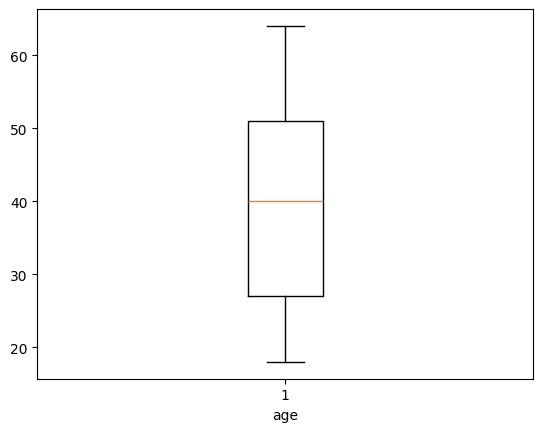

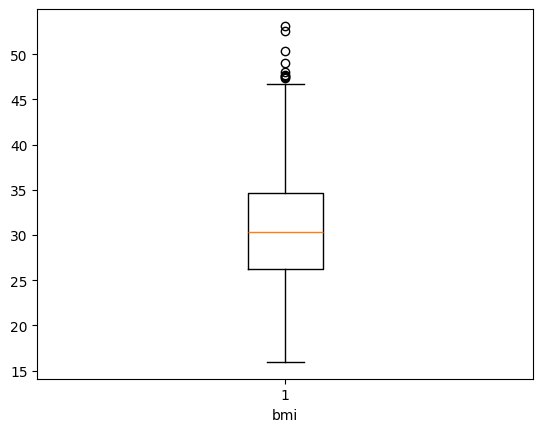

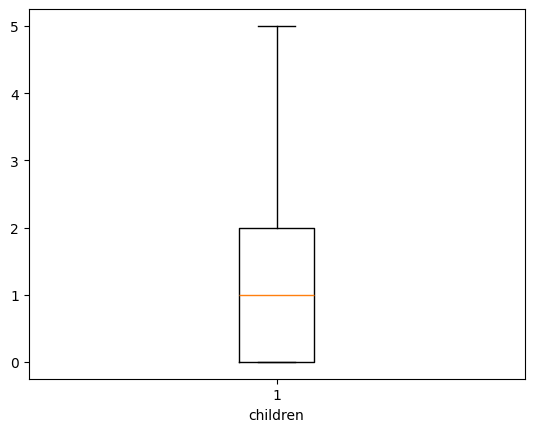

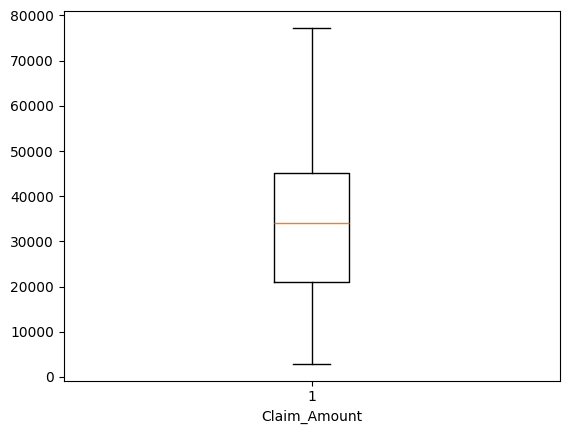

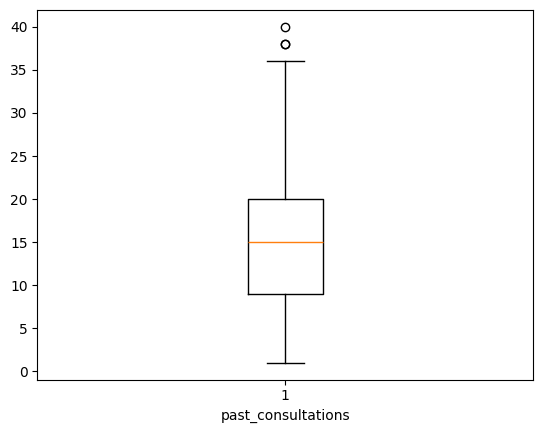

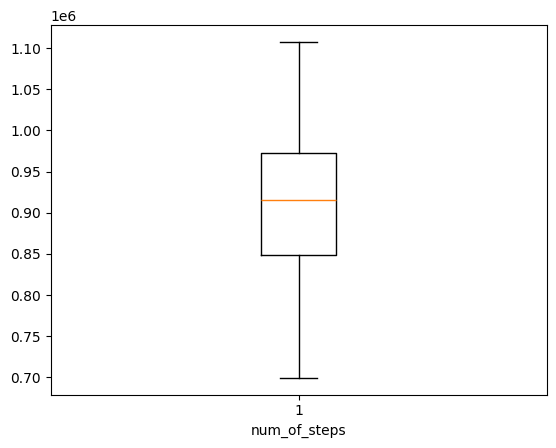

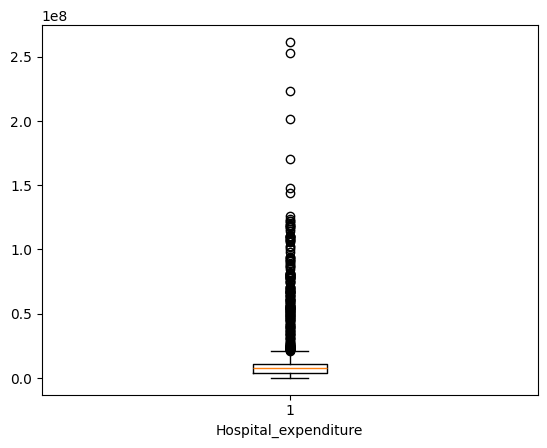

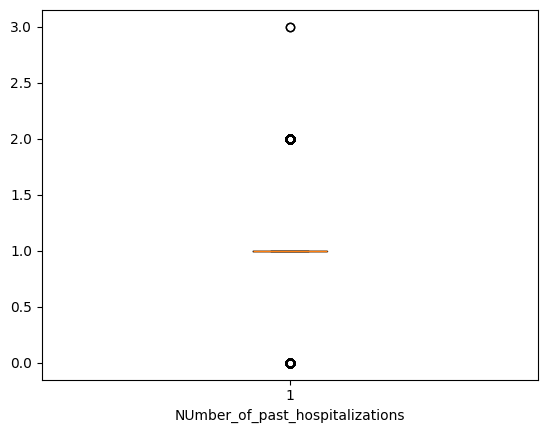

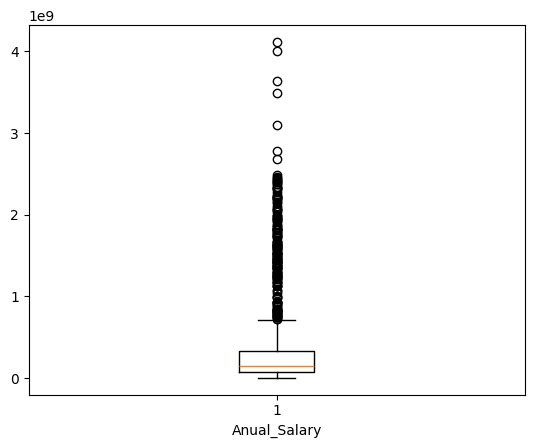

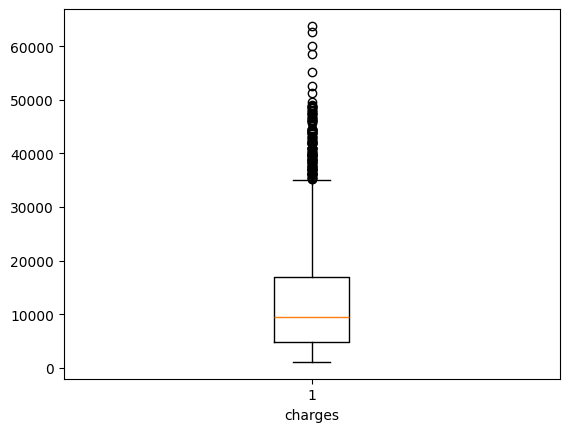

In [ ]:
for i in df.columns:
  if df[i].dtypes == 'int64'or df[i].dtypes == 'float64' :
    plt.boxplot(df[i])
    plt.xlabel(i)
    plt.show()


In [ ]:
for i in df.columns:
  if df[i].dtypes == 'int64'or df[i].dtypes == 'float64' :
    q1 = df[i].quantile(0.25)
    q3 = df[i].quantile(0.75)
    iqr = q3-q1
    ul = q3 + 1.5 * iqr
    ll = q1 - 1.5 * iqr
    df = df[(df[i]>=ll) & (df[i]<=ul)]


In [ ]:
df.shape

(851, 13)

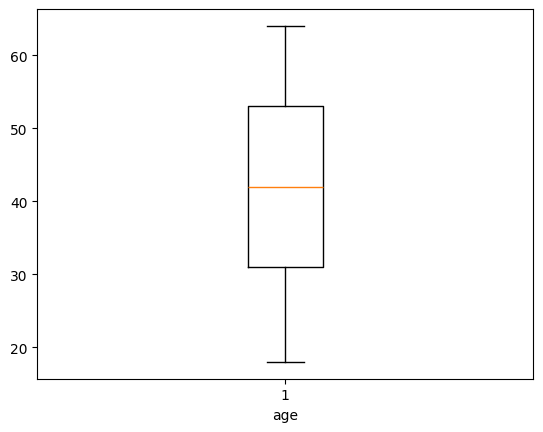

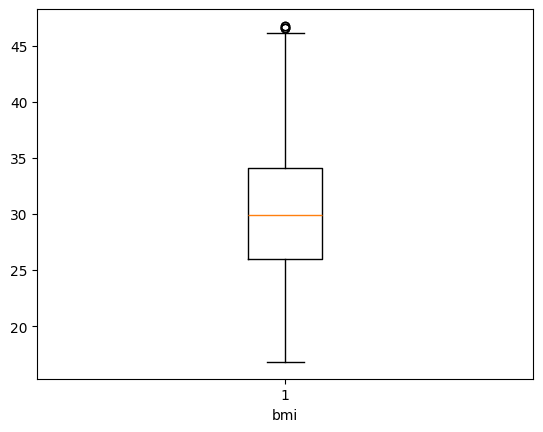

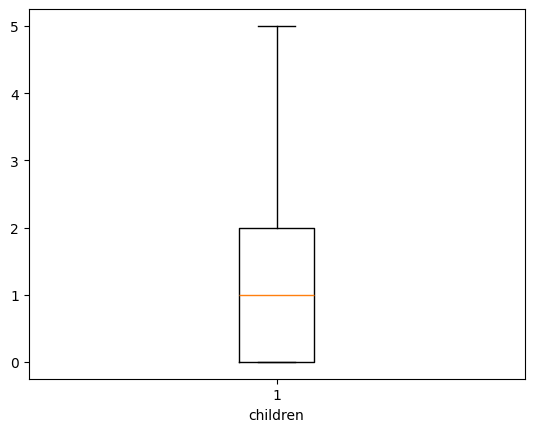

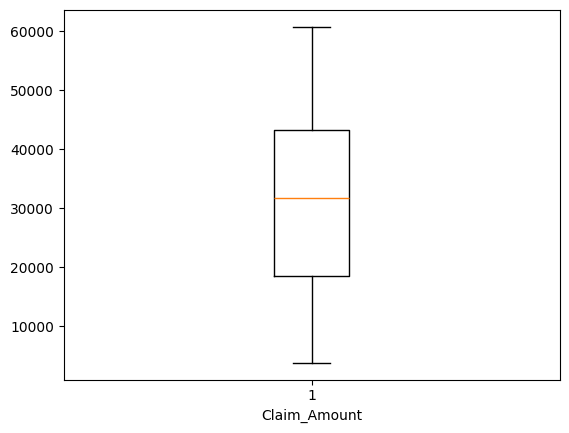

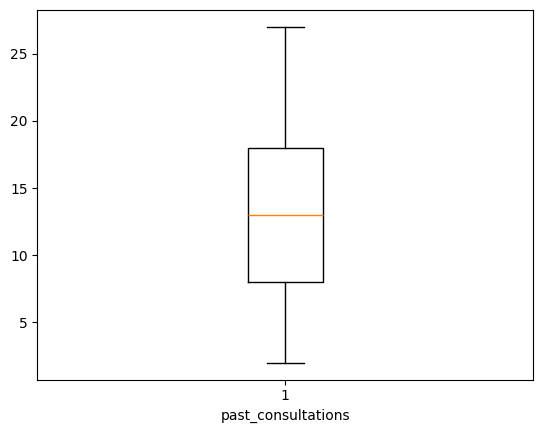

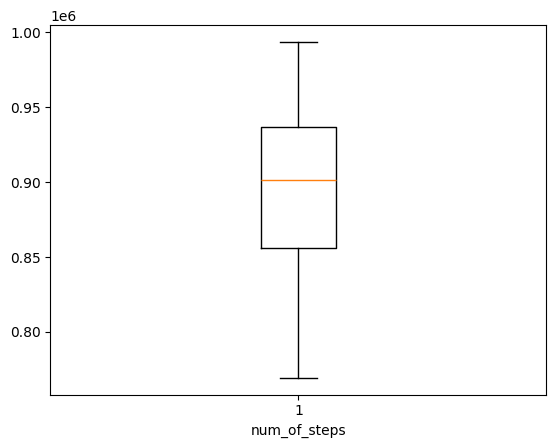

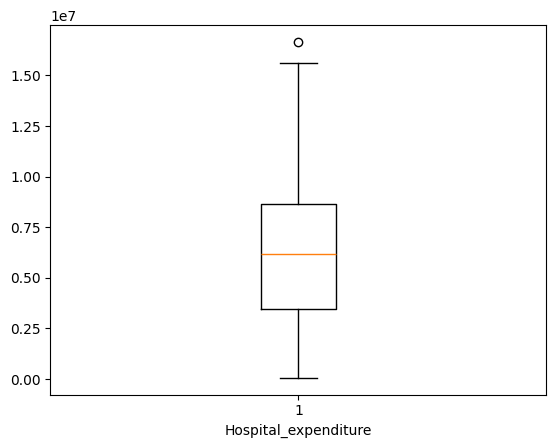

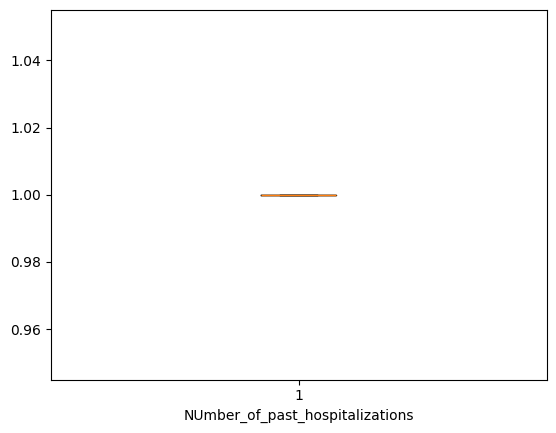

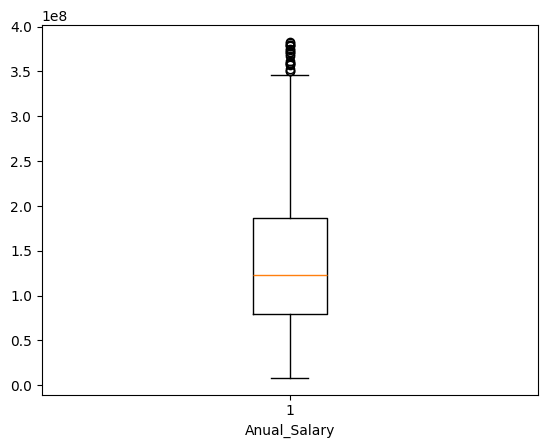

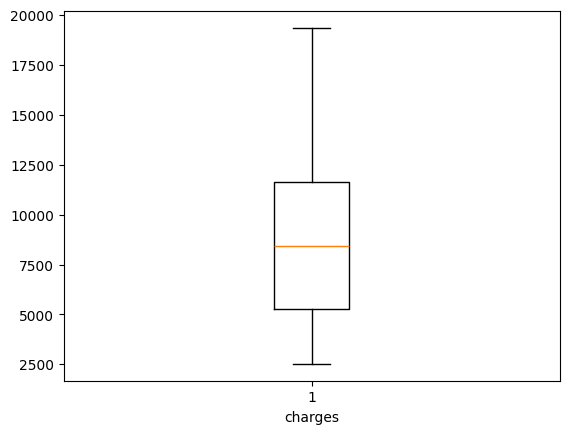

In [ ]:
for i in df.columns:
  if df[i].dtypes == 'int64'or df[i].dtypes == 'float64' :
    plt.boxplot(df[i])
    plt.xlabel(i)
    plt.show()


<Axes: ylabel='count'>

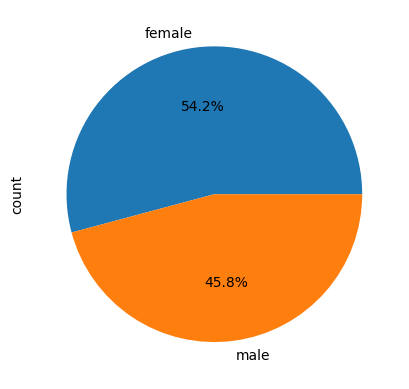

In [ ]:
df['sex'].value_counts().plot.pie(autopct = "%1.1f%%")

In [ ]:
df.groupby('region')['sex'].value_counts()

region     sex   
northeast  female    113
           male      100
northwest  female    120
           male      101
southeast  female    109
           male       93
southwest  female    119
           male       96
Name: count, dtype: int64

In [ ]:
df.groupby('region')['Anual_Salary'].mean()

,Anual_Salary
region,
northeast,1.460747e+08
northwest,1.351207e+08
southeast,1.387155e+08
southwest,1.406074e+08


In [ ]:
df.groupby('region')['charges'].mean().sort_values(ascending=False).head(1)

,charges
region,
northeast,9017.306315


In [ ]:
top_cust = df.sort_values(by='Hospital_expenditure',ascending=False).head(5)
top_cust

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
1046,29.0,female,27.94,1.0,yes,51168.25474,23.0,993751.0,16659821.70,1.0,371218761.2,southeast,19107.7796
1030,30.0,male,24.40,3.0,yes,23306.74970,20.0,980302.0,15602692.79,1.0,379669028.9,southwest,18259.2160
1008,19.0,female,28.30,0.0,yes,54312.36135,15.0,979696.0,14825897.17,1.0,378448282.0,southwest,17081.0800
1036,43.0,male,20.13,2.0,yes,44184.65414,19.0,984247.0,14734508.31,1.0,368787132.4,southeast,18767.7377
1016,32.0,female,24.60,0.0,yes,44462.69482,21.0,993140.0,14371460.85,1.0,342888382.6,southwest,17496.3060


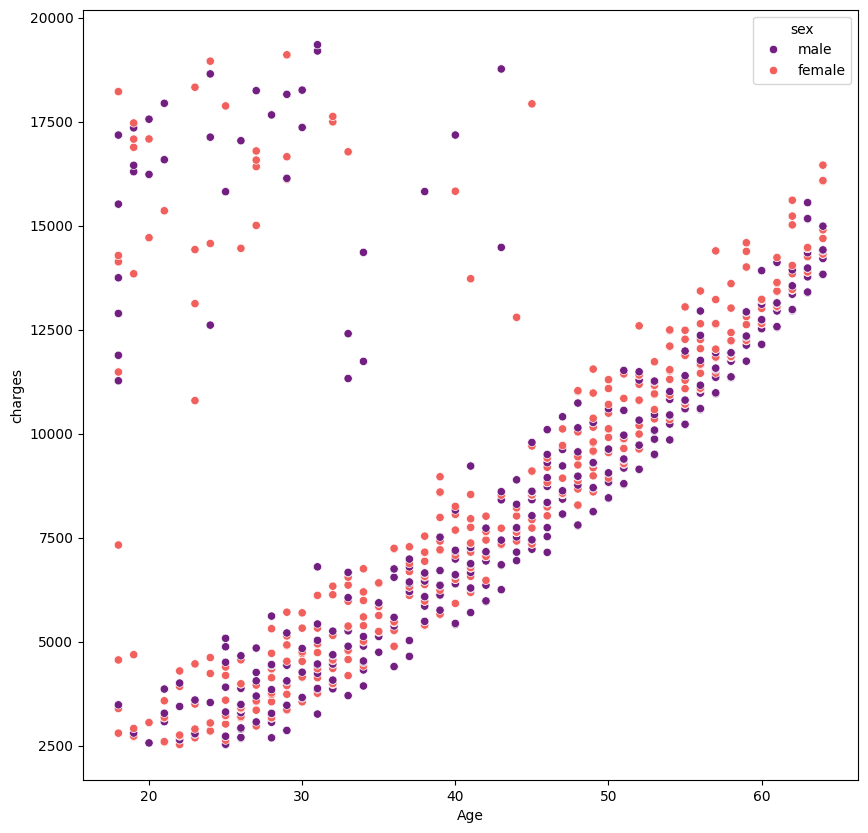

In [ ]:
plt.figure(figsize=(10,10))
sns.scatterplot(data=df,x='age',y='charges',hue='sex',palette='magma')
plt.xlabel('Age')
plt.ylabel('charges')
plt.show()

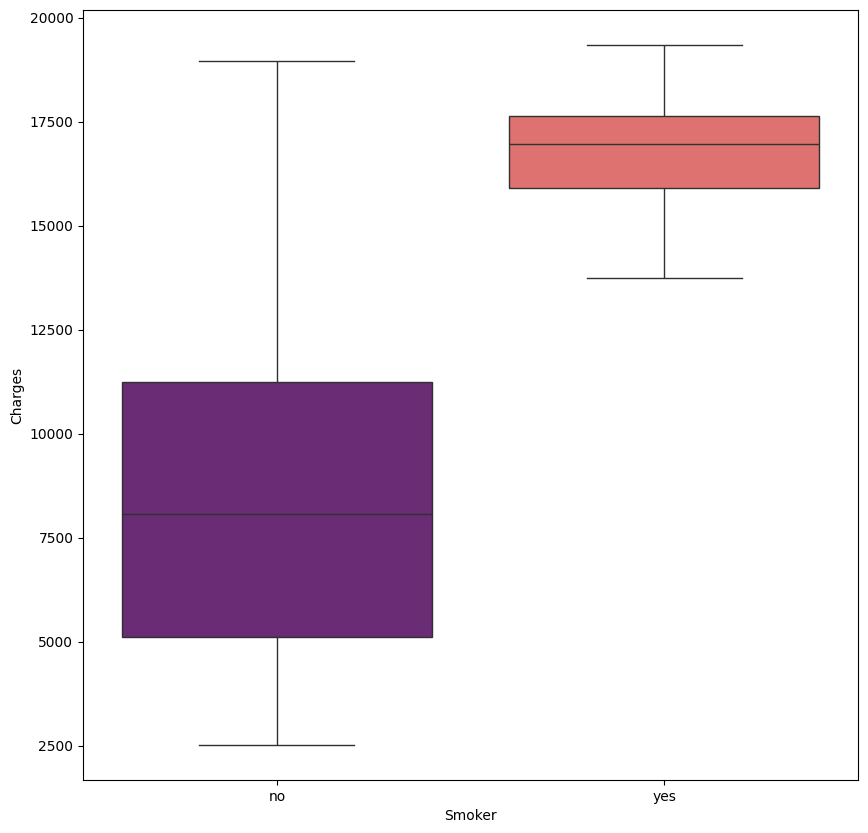

In [ ]:
plt.figure(figsize=(10,10))
sns.boxplot(data=df,x='smoker',y='charges',hue='smoker',palette='magma')
plt.xlabel('Smoker')
plt.ylabel('Charges')
plt.show()